# ST1131 Introduction to Statistics and Statistical Computing
## Topic 6 (Sampling Distributions)

In the lecture, we learnt that a statistic such as the sample mean $\bar{X}$ changes from sample to sample, and that its distribution over all possible samples is called its sampling distribution. In practice, we only ever collect one sample, so we never get to see a sampling distribution directly. In this notebook, we will use Python to simulate drawing many samples from a population, so that we can actually see sampling distributions and check the results from the lecture, including the Central Limit Theorem (CLT).

## Packages

We will use `numpy` to simulate random samples, `matplotlib` to plot histograms, and `norm` from `scipy.stats` (Topic 5) to draw normal curves over our histograms.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

### Random samples in numpy

In Topic 5, we used `binom.rvs` from `scipy.stats` to simulate the DNA example and check its mean and variance. The `numpy` package also has its own functions for drawing random samples, which we will use in this topic:

| Function | Draws from |
|---|---|
| `np.random.normal(mu, sigma, size)` | $N(\mu,\sigma^2)$ |
| `np.random.exponential(scale, size)` | an exponential distribution with mean equal to `scale` |
| `np.random.binomial(n, p, size)` | $Bin(n,p)$ |
| `np.random.choice(values, size)` | a list or array of values, each equally likely |

Just like `norm` in Topic 5, `np.random.normal` takes the standard deviation $\sigma$ and not the variance $\sigma^2$.

The `size` argument can be a single number, which gives a 1D array, or a pair `(rows, columns)`, which gives a 2D array. This is the key to simulating many samples at once. If we want `N` samples each of size `n`, we can draw a 2D array with `N` rows and `n` columns, so that each row is one sample.

As in Topic 5, we use `np.random.seed` to make our results reproducible. We will set the seed again at the start of each section, so that each section gives the same results even if it is run on its own.

## Three different distributions

It is easy to mix up three distributions that appear in this topic:

- The **population distribution** is the distribution of a variable over the entire population.
- The **sample distribution** (or data distribution) is the distribution of the variable in one sample that we collected.
- The **sampling distribution** is the distribution of a statistic, such as $\bar{X}$, over many samples.

### Income example: population distribution

Suppose the monthly income of a population of 1,000,000 people is collected. We will simulate this population using a right-skewed distribution, since income usually has a long tail to the right. You do not need to know the distribution used here, it is just a convenient way to create a realistic-looking population.

Population mean: 8701.72
Population SD: 5026.29


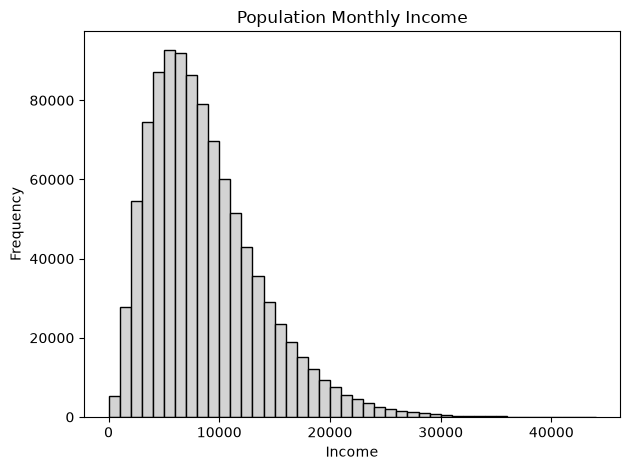

In [4]:
np.random.seed(1131)

population = np.random.gamma(3, 2900, size=1000000) #a right-skewed population of 1,000,000 incomes
mu = population.mean()
sigma = population.std() #population SD, so ddof=0

print(f"Population mean: {round(mu, 2)}")
print(f"Population SD: {round(sigma, 2)}")

plt.figure()
plt.hist(population, bins=np.arange(0,45000,1000), color="lightgray", edgecolor="black")
plt.xlabel("Income")
plt.ylabel("Frequency")
plt.title("Population Monthly Income")
plt.tight_layout()
plt.show()

### Sample distribution

Now we draw a random sample of 1000 people from the population using `np.random.choice`. The histogram of this one sample is the sample distribution. Notice that it has roughly the same shape as the population, just with fewer observations.

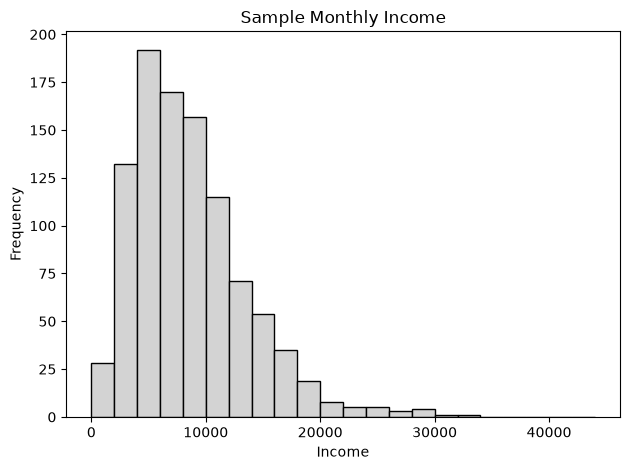

Sample mean: 8578.85


In [5]:
sample = np.random.choice(population, size=1000)

plt.figure()
plt.hist(sample, bins=np.arange(0,45000,2000), color="lightgray", edgecolor="black")
plt.xlabel("Income")
plt.ylabel("Frequency")
plt.title("Sample Monthly Income")
plt.tight_layout()
plt.show()

print(f"Sample mean: {round(sample.mean(), 2)}")

### Sampling distribution

The sample mean above is one value of $\bar{X}$. If we collected another sample of 1000, we would get a different sample mean. Let's collect 9999 more samples, so that we have 10000 samples in total, and calculate the mean of each sample.

We draw all 10000 samples at once as a 2D array with 10000 rows and 1000 columns, where each row is one sample. Taking the mean with `axis=1` averages across each row, as we saw in Topic 1, giving us 10000 sample means. The histogram of these sample means is the (simulated) sampling distribution of $\bar{X}$.

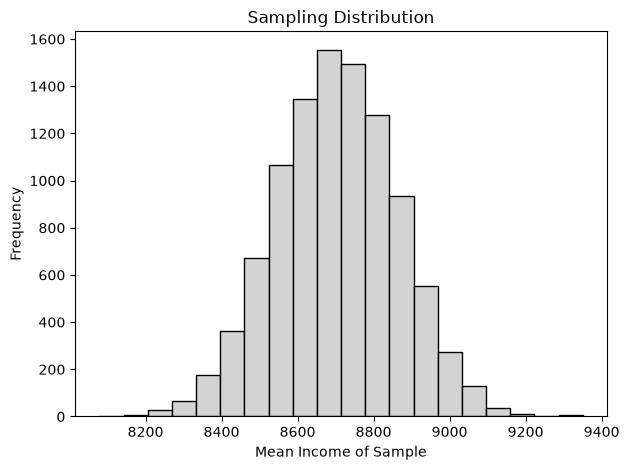

In [6]:
N_samples = np.random.choice(population, size=(10000, 1000)) #10000 rows, each row is a sample of 1000
sample_means = N_samples.mean(axis=1) #10000 sample means, one for each row

plt.figure()
plt.hist(sample_means, bins=20, color="lightgray", edgecolor="black")
plt.xlabel("Mean Income of Sample")
plt.ylabel("Frequency")
plt.title("Sampling Distribution")
plt.tight_layout()
plt.show()

Even though the population is skewed, the sampling distribution of $\bar{X}$ is bell-shaped and centred at the population mean. It is also far narrower than the population, since the means vary much less than individual incomes do. From the lecture, the sampling distribution should have mean $\mu$ and standard deviation $\sigma/\sqrt{n}$.

In [7]:
print(f"Mean of the sample means: {round(np.mean(sample_means), 2)}")
print(f"Population mean mu: {round(mu, 2)}")
print(f"SD of the sample means: {round(np.std(sample_means, ddof=1), 2)}")
print(f"sigma/sqrt(n): {round(sigma/np.sqrt(1000), 2)}")

Mean of the sample means: 8702.64
Population mean mu: 8701.72
SD of the sample means: 159.77
sigma/sqrt(n): 158.95


Recall from Topic 1 that `np.std` gives the population standard deviation by default, and `ddof=1` gives the sample standard deviation. We use `ddof=1` for the sample means because they are a sample of all possible sample means.

## Practice Example 1

Assume that the score on a recent midterm is normally distributed with population mean $\mu=70$ and population standard deviation $\sigma=10$. You randomly sample 12 students who took the midterm.

### (a) One sample

Simulate drawing one sample of size 12. What sample mean score do you get? Why do you not expect to get exactly 70?

In [8]:
np.random.seed(999)

n = 12
mu = 70
sigma = 10

x = np.random.normal(mu, sigma, size=n)
print(x)

x = np.round(x, 1) #round to 1 decimal place
print(x)

sample_mean = np.mean(x)
print(f"Sample mean: {round(sample_mean, 2)}")

[71.27157844 84.01890882 73.14814987 61.41550836 67.33865563 63.5109929
 85.66267569 49.08629809 84.56328064 79.45293415 65.99798806 73.15227304]
[71.3 84.  73.1 61.4 67.3 63.5 85.7 49.1 84.6 79.5 66.  73.2]
Sample mean: 71.56


The sample mean is not exactly 70 because it is calculated from only 12 randomly chosen students. A different sample of 12 students would give a different sample mean. The sample mean is a random variable that varies from sample to sample around the population mean of 70.

### (b) Many samples

Now, simulate drawing 10000 samples of size 12 each. Describe the simulated sampling distribution by using the histogram of the 10000 sample means you generated.

In [9]:
n = 12
mu = 70
sigma = 10
N = 10000

N_samples = np.random.normal(mu, sigma, size=(N, n)) #N rows, each row is a random sample of n from N(70, 10^2)
print(N_samples.shape)

sample_means = N_samples.mean(axis=1) #the mean of each row, giving N sample means
print(sample_means[:8]) #first 8 sample means

(10000, 12)
[67.66803746 69.83312582 72.92205565 72.46651614 73.19079613 74.22277696
 74.62713676 71.61562924]


In [10]:
print(f"Mean of the sample means: {round(np.mean(sample_means), 4)}") #should be close to 70
print(f"SD of the sample means: {round(np.std(sample_means, ddof=1), 4)}") #should be close to sigma/sqrt(n)
print(f"sigma/sqrt(n): {round(sigma/np.sqrt(n), 4)}")

Mean of the sample means: 69.9823
SD of the sample means: 2.8865
sigma/sqrt(n): 2.8868


Since the population is normal, the lecture tells us that $\bar{X}\sim N(\mu,\sigma^2/n)$ exactly, for any sample size. We can check this by drawing the pdf of $N(70,10^2/12)$ over the histogram. Using `density=True` from Topic 2 puts the histogram on the same scale as the pdf.

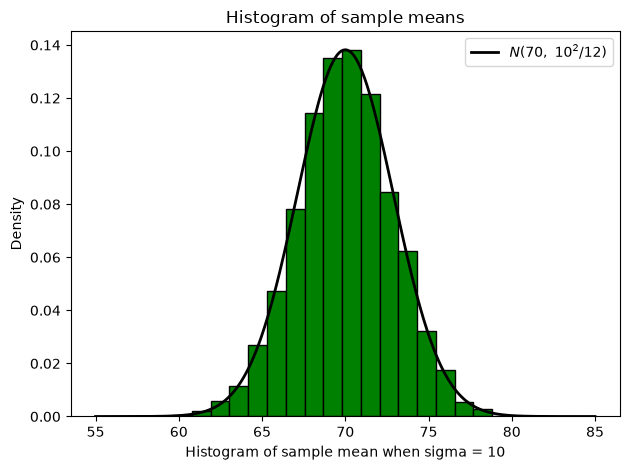

In [11]:
xs = np.linspace(55,85,400)

plt.figure()
plt.hist(sample_means, bins=20, density=True, color="green", edgecolor="black")
plt.plot(xs, norm.pdf(xs, mu, sigma/np.sqrt(n)), color="black", linewidth=2, label=r"$N(70,\ 10^2/12)$")
plt.xlabel("Histogram of sample mean when sigma = 10")
plt.ylabel("Density")
plt.title("Histogram of sample means")
plt.legend()
plt.tight_layout()
plt.show()

The histogram is bell-shaped and symmetric, centred close to 70, with a standard deviation close to $10/\sqrt{12}=2.89$. The normal curve fits the histogram closely.

### (c) A smaller population standard deviation

Suppose the population standard deviation is 5 instead of 10. How does the simulated sampling distribution of the sample mean change? Notice that the code is the same as in (b), we only change the value of `sigma`.

In [12]:
n = 12
mu = 70
sigma = 5
N = 10000

N_samples = np.random.normal(mu, sigma, size=(N, n))
sample_means_5 = N_samples.mean(axis=1)

print(f"Mean of the sample means: {round(np.mean(sample_means_5), 4)}") #should be close to 70
print(f"SD of the sample means: {round(np.std(sample_means_5, ddof=1), 4)}") #should be close to sigma/sqrt(n)
print(f"sigma/sqrt(n): {round(sigma/np.sqrt(n), 4)}")

Mean of the sample means: 70.0149
SD of the sample means: 1.4366
sigma/sqrt(n): 1.4434


To compare the two sampling distributions fairly, we plot them side by side with `plt.subplots` (Topic 5). Setting `sharex=True` makes both plots use the same horizontal axis.

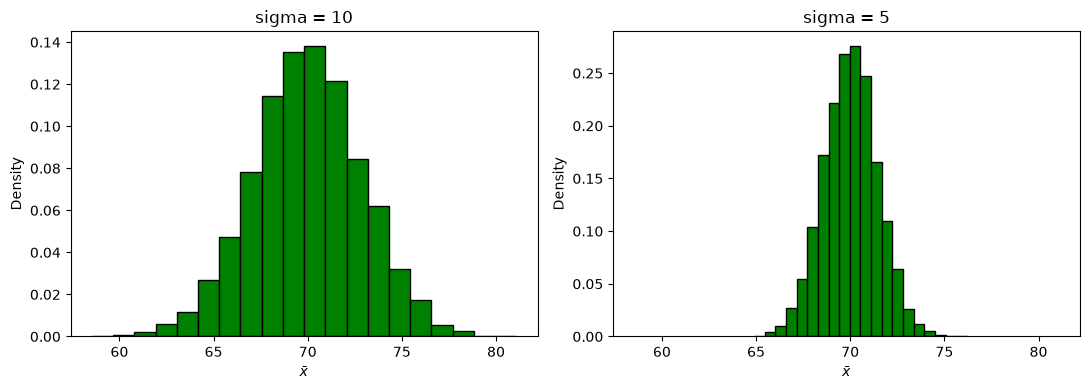

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11,4), sharex=True)

axes[0].hist(sample_means, bins=20, density=True, color="green", edgecolor="black")
axes[0].set_title("sigma = 10")
axes[0].set_xlabel(r"$\bar{x}$")
axes[0].set_ylabel("Density")

axes[1].hist(sample_means_5, bins=20, density=True, color="green", edgecolor="black")
axes[1].set_title("sigma = 5")
axes[1].set_xlabel(r"$\bar{x}$")
axes[1].set_ylabel("Density")

plt.tight_layout()
plt.show()

Both sampling distributions are bell-shaped and centred at 70, but with $\sigma=5$ the sampling distribution is narrower. Its standard deviation is about half of before ($5/\sqrt{12}=1.44$ compared to $2.89$), since $\sigma/\sqrt{n}$ is proportional to $\sigma$. A less variable population gives more precise sample means.

## Practice Example 2

Consider the income of a population which follows a non-normal distribution (an exponential distribution) with mean $\lambda$. A random sample of individuals is collected from this population to estimate $\lambda$. Let $\bar{x}$ denote the sample mean. By the Central Limit Theorem, when the sample size $n$ is large enough, $\bar{x}$ will approximately follow a normal distribution with mean $\lambda$ and standard deviation $\lambda/\sqrt{n}$. Let's assume $\lambda=5000$.

### The population distribution

Before we start, let's look at the population. We draw a large number of values with `np.random.exponential`, where the `scale` argument is the mean $\lambda$. The population is very right-skewed, and nothing like a normal distribution.

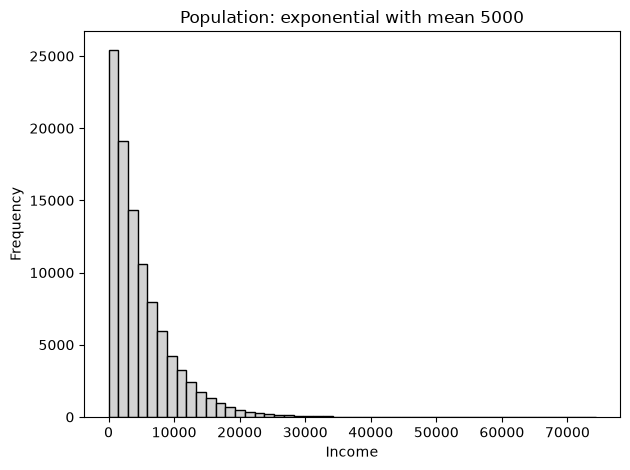

In [14]:
np.random.seed(151)

lam = 5000 #lambda is a reserved keyword in Python, so we use lam instead

plt.figure()
plt.hist(np.random.exponential(scale=lam, size=100000), bins=50, color="lightgray", edgecolor="black")
plt.xlabel("Income")
plt.ylabel("Frequency")
plt.title("Population: exponential with mean 5000")
plt.tight_layout()
plt.show()

Take note that we cannot name our variable `lambda`, since `lambda` is a reserved keyword in Python (we used it in Topic 2 to create small functions). This is why we use `lam`.

### (a) Simulating the sample means

Simulate $N$ samples, each of size $n$, where $N=1000$ and $n=50$. Derive $\bar{x}$ for each of the $N$ samples.

In [15]:
lam = 5000
N = 1000
n = 50

N_samples = np.random.exponential(scale=lam, size=(N, n)) #N rows, each row has 50 values from the exponential
ave = N_samples.mean(axis=1) #all 1000 values of the sample mean

print(ave[:8]) #first 8 values of x-bar

[4602.26004216 5050.34162774 5973.17335294 4304.73625644 5791.79670086
 5836.01536891 4435.48550778 5880.70485607]


### (b) The sampling distribution for n = 50

Plot a histogram of these $\bar{x}$. Does the histogram have a bell curve resembling a normal distribution? What are the mean and standard deviation of these $\bar{x}$?

Mean of x-bar: 4995.49
SD of x-bar: 698.2
lambda/sqrt(n): 707.11


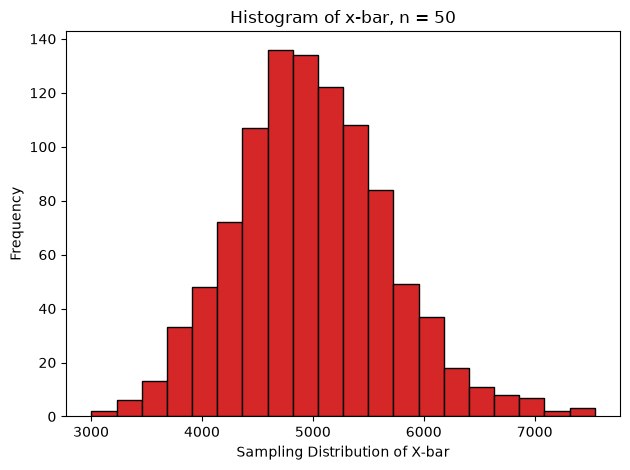

In [16]:
print(f"Mean of x-bar: {round(np.mean(ave), 2)}") #should be close to lambda
print(f"SD of x-bar: {round(np.std(ave, ddof=1), 2)}") #should be close to lambda/sqrt(n)
print(f"lambda/sqrt(n): {round(lam/np.sqrt(n), 2)}")

plt.figure()
plt.hist(ave, bins=20, color="tab:red", edgecolor="black")
plt.xlabel("Sampling Distribution of X-bar")
plt.ylabel("Frequency")
plt.title("Histogram of x-bar, n = 50")
plt.tight_layout()
plt.show()

Even though the population is heavily skewed, the histogram of $\bar{x}$ is roughly bell-shaped and centred close to 5000, with a standard deviation close to $5000/\sqrt{50}=707$. This is the CLT in action.

### (c) The sampling distribution for n = 7

Repeat the two questions above with the same $N=1000$ but $n=7$. Does the histogram resemble a normal distribution? Comment on the effect of the sample size $n$ on the normal approximation of the distribution of $\bar{x}$.

Mean of x-bar: 4936.59
SD of x-bar: 1916.99
lambda/sqrt(n): 1889.82


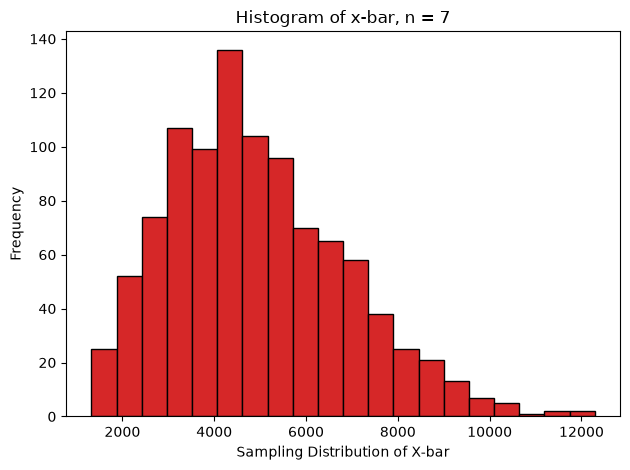

In [17]:
lam = 5000
N = 1000
n = 7

N_samples = np.random.exponential(scale=lam, size=(N, n)) #N rows, each row has 7 values from the exponential
ave_7 = N_samples.mean(axis=1)

print(f"Mean of x-bar: {round(np.mean(ave_7), 2)}") #should be close to lambda
print(f"SD of x-bar: {round(np.std(ave_7, ddof=1), 2)}") #should be close to lambda/sqrt(n)
print(f"lambda/sqrt(n): {round(lam/np.sqrt(n), 2)}")

plt.figure()
plt.hist(ave_7, bins=20, color="tab:red", edgecolor="black")
plt.xlabel("Sampling Distribution of X-bar")
plt.ylabel("Frequency")
plt.title("Histogram of x-bar, n = 7")
plt.tight_layout()
plt.show()

With $n=7$, the histogram is still clearly right-skewed, so a normal distribution is not a good approximation. Its mean is still close to 5000 and its standard deviation is still close to $\lambda/\sqrt{n}$, since these two facts hold for any $n$. What the CLT needs a large $n$ for is the **shape**.

To see the effect of $n$ more clearly, we can put the two histograms side by side and draw the normal curve suggested by the CLT, $N(\lambda,\lambda^2/n)$, over each one.

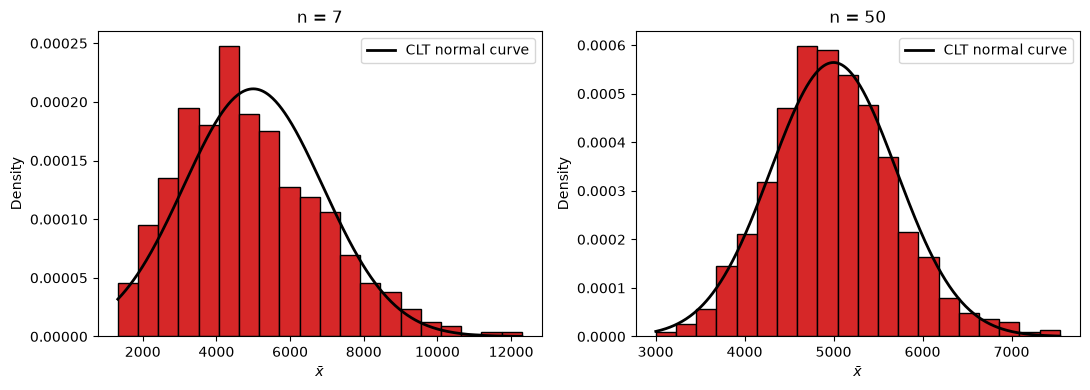

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11,4))

for ax, values, n in zip(axes, [ave_7, ave], [7, 50]):
    xs = np.linspace(values.min(), values.max(), 400)
    ax.hist(values, bins=20, density=True, color="tab:red", edgecolor="black")
    ax.plot(xs, norm.pdf(xs, lam, lam/np.sqrt(n)), color="black", linewidth=2, label="CLT normal curve")
    ax.set_title(f"n = {n}")
    ax.set_xlabel(r"$\bar{x}$")
    ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()
plt.show()

The normal curve fits poorly when $n=7$, but fits well when $n=50$. As the sample size $n$ increases, the sampling distribution of $\bar{x}$ becomes more symmetric and closer to a normal distribution, and it also becomes narrower. This agrees with the rule of thumb of $n\ge30$ from the lecture. The more skewed the population, the larger $n$ needs to be.

## Sample size $n$ versus number of samples $N$

In our simulations, there are two different numbers, and it is important not to confuse them:

- $n$ is the size of each sample. Changing $n$ changes the true sampling distribution of $\bar{X}$ (its spread, and for skewed populations, its shape).
- $N$ is the number of samples we simulate. Changing $N$ does **not** change the true sampling distribution. It only changes how well our histogram approximates it.

In real life, we only collect one sample, so $N$ only exists in simulations. Let's check this with IQ as an example, IQ $\sim N\left(100,15^2\right)$ with samples of size $n=5$, so the true sampling distribution is $N\left(100,15^2/5\right)$.

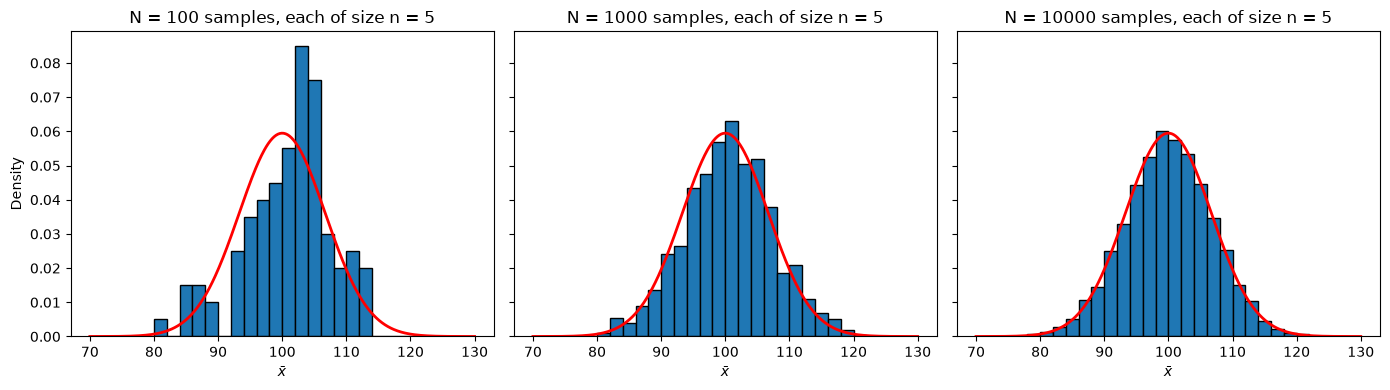

In [19]:
np.random.seed(2026)

mu = 100
sigma = 15
n = 5
xs = np.linspace(70,130,400)

fig, axes = plt.subplots(1, 3, figsize=(14,4), sharey=True)

for ax, N in zip(axes, [100, 1000, 10000]):
    sample_means = np.random.normal(mu, sigma, size=(N, n)).mean(axis=1)
    ax.hist(sample_means, bins=np.arange(70,131,2), density=True, color="tab:blue", edgecolor="black")
    ax.plot(xs, norm.pdf(xs, mu, sigma/np.sqrt(n)), color="red", linewidth=2)
    ax.set_title(f"N = {N} samples, each of size n = {n}")
    ax.set_xlabel(r"$\bar{x}$")

axes[0].set_ylabel("Density")
plt.tight_layout()
plt.show()

The red curve, which is the true sampling distribution, is the same in all three plots because $n$ stays at 5. With more samples $N$, the histogram becomes smoother and follows the red curve more closely.

## Sampling distribution of the sample proportion

The same idea works for the sample proportion $\hat{p}$. In the lecture's election example, $n=3889$ voters were surveyed and $\hat{p}=0.531$ voted for Brown. If each voter is a Bernoulli trial with probability $p$, then the number of Brown voters in a sample is $Bin(n,p)$, and $\hat{p}$ is that number divided by $n$. We know that $\hat{p}$ is approximately $N\left(p,p(1-p)/n\right)$.

We can simulate 10000 polls using `np.random.binomial`, taking $p=0.531$ as the true proportion.

Mean of p-hat: 0.531
SD of p-hat: 0.0079
sqrt(p(1-p)/n): 0.008


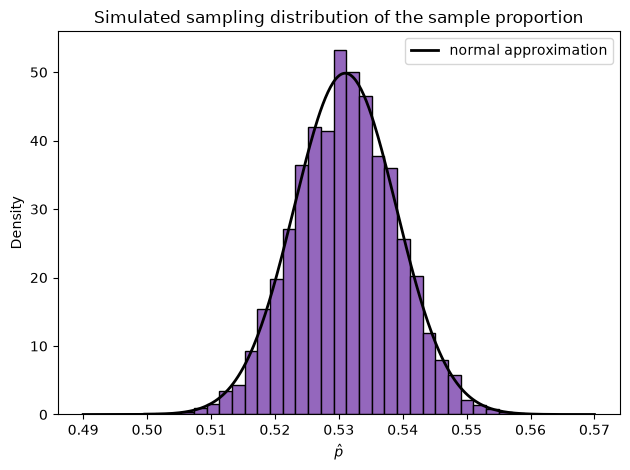

In [20]:
np.random.seed(3889)

n = 3889
p = 0.531
N = 10000

p_hat = np.random.binomial(n, p, size=N)/n #N sample proportions

print(f"Mean of p-hat: {round(np.mean(p_hat), 4)}") #should be close to p
print(f"SD of p-hat: {round(np.std(p_hat, ddof=1), 4)}") #should be close to sqrt(p(1-p)/n)
print(f"sqrt(p(1-p)/n): {round(np.sqrt(p*(1-p)/n), 4)}")

xs = np.linspace(0.49,0.57,400)

plt.figure()
plt.hist(p_hat, bins=30, density=True, color="tab:purple", edgecolor="black")
plt.plot(xs, norm.pdf(xs, p, np.sqrt(p*(1-p)/n)), color="black", linewidth=2, label="normal approximation")
plt.xlabel(r"$\hat{p}$")
plt.ylabel("Density")
plt.title("Simulated sampling distribution of the sample proportion")
plt.legend()
plt.tight_layout()
plt.show()

The simulated $\hat{p}$ values are centred at 0.531 with a standard deviation of about 0.008, matching the standard error from the lecture. Almost all of them lie within 3 standard errors, between 0.507 and 0.555. We can check the proportion directly, where `np.mean` of a boolean array gives the proportion of `True` values.

In [21]:
se = np.sqrt(p*(1-p)/n)
print(f"Proportion of p-hat within 3 SE of p: {np.mean(np.abs(p_hat-p)<=3*se)}")

Proportion of p-hat within 3 SE of p: 0.9976


## Online Shiny app

You can try using this website by Dr David Chew to play around with some population distributions with different parameters, to see how the sample distribution and sampling distribution will look like: https://david-chew.shinyapps.io/CLT4means/